# Pollutant data

In [1]:
import pandas as pd
import os
from utils import read_files
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# this folder is not on GitHub, because it's too large
path = "data/ugz_pollutants_h1/"

files_pollutants = os.listdir(path)

for i in range(len(files_pollutants)):
    files_pollutants[i] = os.path.join(path, files_pollutants[i])

df_pollutants = read_files(file_paths=files_pollutants, drop_columns=["Intervall", "Status"], date_column="Datum")#, UTC=False)

columns_pollutants = df_pollutants.columns

#df_pollutants = df_pollutants.drop(columns=[columns_pollutants[3], columns_pollutants[6], columns_pollutants[8]])
columns_pollutants = df_pollutants.columns
#print(columns_pollutants)
df_pollutants

,Datum,Standort,Parameter,Einheit,Wert,Year,Datetime
0,2017-01-01T00:00+0100,Zch_Heubeeribüel,NO2,µg/m3,36.78,2017,2017-01-01 00:00:00+01:00
1,2017-01-01T00:00+0100,Zch_Heubeeribüel,NO,µg/m3,6.96,2017,2017-01-01 00:00:00+01:00
2,2017-01-01T00:00+0100,Zch_Heubeeribüel,NOx,ppb,24.82,2017,2017-01-01 00:00:00+01:00
3,2017-01-01T00:00+0100,Zch_Heubeeribüel,O3,µg/m3,1.82,2017,2017-01-01 00:00:00+01:00
4,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,NO2,µg/m3,39.79,2017,2017-01-01 00:00:00+01:00
...,...,...,...,...,...,...,...
1479206,2024-12-31T23:00+0100,Zch_Rosengartenstrasse,NO,µg/m3,18.58,2024,2024-12-31 23:00:00+01:00
1479207,2024-12-31T23:00+0100,Zch_Rosengartenstrasse,NO2,µg/m3,47.51,2024,2024-12-31 23:00:00+01:00
1479208,2024-12-31T23:00+0100,Zch_Rosengartenstrasse,O3,µg/m3,1.28,2024,2024-12-31 23:00:00+01:00
1479209,2024-12-31T23:00+0100,Zch_Rosengartenstrasse,PM10,µg/m3,48.01,2024,2024-12-31 23:00:00+01:00


In [ ]:
#station_map = {
#    "Rosengartenstrasse (Nordstrasse)": "Zch_Rosengartenstrasse",
#    "Stampfenbachstrasse (Wasserwerkstrasse)": "Zch_Stampfenbachstrasse",
#    "Schimmelstrasse (Werdstrasse)": "Zch_Schimmelstrasse",
#    "Zürichbergstrasse (Dreiwiesenstrasse)": "Zch_Heubeeribüel"
#}

In [ ]:
#df_meteo = df_meteo[df_meteo["Standort"].isin(station_map)]

In [4]:
df_pollutants["pollutant_station"] = df_pollutants["Standort"]#.map(station_map)

In [5]:
df_pollutants.head()

,Datum,Standort,Parameter,Einheit,Wert,Year,Datetime,pollutant_station
0,2017-01-01T00:00+0100,Zch_Heubeeribüel,NO2,µg/m3,36.78,2017,2017-01-01 00:00:00+01:00,Zch_Heubeeribüel
1,2017-01-01T00:00+0100,Zch_Heubeeribüel,NO,µg/m3,6.96,2017,2017-01-01 00:00:00+01:00,Zch_Heubeeribüel
2,2017-01-01T00:00+0100,Zch_Heubeeribüel,NOx,ppb,24.82,2017,2017-01-01 00:00:00+01:00,Zch_Heubeeribüel
3,2017-01-01T00:00+0100,Zch_Heubeeribüel,O3,µg/m3,1.82,2017,2017-01-01 00:00:00+01:00,Zch_Heubeeribüel
4,2017-01-01T00:00+0100,Zch_Rosengartenstrasse,NO2,µg/m3,39.79,2017,2017-01-01 00:00:00+01:00,Zch_Rosengartenstrasse


In [7]:
param_units_pollutants = (
    df_pollutants[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_pollutants

,Parameter,Einheit
0,NO2,µg/m3
1,NO,µg/m3
2,NOx,ppb
3,O3,µg/m3
4,PM10,µg/m3
5,PM2.5,µg/m3
6,CO,mg/m3
7,SO2,µg/m3


In [42]:
# --- 1) Parse datetime and split date/time ---
df_pollutants["Datetime"] = pd.to_datetime(df_pollutants["Datetime"], errors="coerce")
df_pollutants["Datum_date"] = df_pollutants["Datetime"].dt.date   # Python date objects
df_pollutants["Datum_time"] = df_pollutants["Datetime"].dt.time   # Python time objects

df_pollutants


columns_pollutants = df_pollutants.columns
print(columns_pollutants)

Index(['Datum', 'Standort', 'Parameter', 'Einheit', 'Wert', 'Year', 'Datetime',
       'pollutant_station', 'Datum_date', 'Datum_time'],
      dtype='object')


In [48]:
# Pivot with split date and time columns

# 1) Parse 'Datum' as timezone-aware datetime
# Pandas can parse 'YYYY-MM-DDTHH:MM+0100' directly.
df_pollutants["Datum"] = pd.to_datetime(df_pollutants["Datum"], errors="coerce")

# 2) Create date and time columns
df_pollutants["Datum_date"] = df_pollutants["Datum"].dt.date      # dtype: object (date objects)
df_pollutants["Datum_time"] = df_pollutants["Datum"].dt.time      # dtype: object (time objects)    
# Optional: if you prefer pure pandas dtypes (no Python date/time objects),
# you can keep them as strings or as datetime64:
# df_meteo["Datum_date"] = df_meteo["Datum"].dt.strftime("%Y-%m-%d")
# df_meteo["Datum_time"] = df_meteo["Datum"].dt.strftime("%H:%M:%S%z")

# 3) Now pivot using the original 'Datum' or the split columns as needed
df_pollutants_pivot = df_pollutants.pivot(
    #index=["Datum", "Standort"], 
    index = ['Year', 'Datetime', 'Datum_date','Datum_time','Standort'], # you can also use ['Datum_date','Datum_time','Standort']
    columns="Parameter",
    values="Wert"
)


# --- 3) Drop unwanted pollutant columns (if present) ---
cols_to_drop = ["CO", "O3_max_h1", "O3_nb_h1>120", "SO2", "PN"]
df_pollutants_pivot = df_pollutants_pivot.drop(
    columns=[c for c in cols_to_drop if c in df_pollutants_pivot.columns],
    errors="ignore"
)

# --- 4) Remove the column index name ('Parameter') immediately ---
df_pollutants_pivot.columns.name = None

# --- 5) Reset index so keys become columns (flat DataFrame) ---
df_pollutants_pivot = df_pollutants_pivot.reset_index()   # unfortunately this is needed, otherwise the parameter names are in separate row

# At this point, df_pollutants_pivot has columns:
# ['Datum_date', 'Datum_time', 'Standort', 'NO', 'NO2', 'NOx', 'O3', 'PM10', 'PM2.5', ...]
# with NO extra header name for the pollutant columns.
df_pollutants_pivot

,Year,Datetime,Datum_date,Datum_time,Standort,NO,NO2,NOx,O3,PM10,PM2.5
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54
3,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
245371,2024,2024-12-31 22:00:00+01:00,2024-12-31,22:00:00,Zch_Stampfenbachstrasse,5.82,43.03,27.17,3.80,27.02,25.49
245372,2024,2024-12-31 23:00:00+01:00,2024-12-31,23:00:00,Zch_Heubeeribüel,2.42,39.25,22.47,6.34,21.09,21.07
245373,2024,2024-12-31 23:00:00+01:00,2024-12-31,23:00:00,Zch_Rosengartenstrasse,18.58,47.51,39.74,1.28,48.01,51.00
245374,2024,2024-12-31 23:00:00+01:00,2024-12-31,23:00:00,Zch_Schimmelstrasse,15.28,46.48,36.55,4.20,35.89,38.17


In [ ]:
desired_order = ["Year", "Datetime", "Datum_date", "Datum_time", "Standort"]
df_pollutants_pivot = df_pollutants_pivot[desired_order + [col for col in df_pollutants_pivot.columns if col not in desired_order]]
df_pollutants_pivot.head()

,Year,Datetime,Datum_date,Datum_time,Standort,NO,NO2,NOx,O3,PM10,PM2.5
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54
3,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN


In [29]:
# Display df_pollutants info and missing values
print("df_pollutants shape:", df_pollutants_pivot.shape)
print("\nMissing values per column:")
print(df_pollutants_pivot.isnull().sum())
print("\nData types:")
print(df_pollutants_pivot.dtypes)

df_pollutants shape: (245376, 11)

Missing values per column:
Datetime          0
Datum_date        0
Datum_time        0
Standort          0
Year              0
NO             4348
NO2            4367
NOx            4364
O3             3678
PM10          57303
PM2.5         67098
dtype: int64

Data types:
Datetime      datetime64[ns, Europe/Zurich]
Datum_date                           object
Datum_time                           object
Standort                             object
Year                                  int64
NO                                  float64
NO2                                 float64
NOx                                 float64
O3                                  float64
PM10                                float64
PM2.5                               float64
dtype: object


In [30]:
# --- Identify key and parameter columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_pollutants_pivot.columns]
pollutant_cols = [c for c in df_pollutants_pivot.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only).")

# Ensure date-only type for coverage stats
df_pollutants_pivot["Datum_date"] = pd.to_datetime(df_pollutants_pivot["Datum_date"], errors="coerce").dt.date
# --- Station-level base coverage: rows & date span ---
base = (df_pollutants_pivot
        .groupby("Standort", as_index=True)
        .agg(n_rows=("Standort", "size"),
             n_days=("Datum_date", "nunique"),
             min_date=("Datum_date", "min"),
             max_date=("Datum_date", "max")))

# --- Missing counts per pollutant (per station) ---
miss_by_station = (df_pollutants_pivot[pollutant_cols]
                   .isna()
                   .groupby(df_pollutants_pivot["Standort"])
                   .sum())

# --- Missing rates per pollutant (divide by the station's row count) ---
#miss_rate_by_station = miss_by_station.div(base["n_rows"], axis=0)

# --- Combined wide summary (counts + rates, alongside coverage) ---
summary_wide = (base
                .join(miss_by_station.add_prefix("miss_"))
                #.join(miss_rate_by_station.add_prefix("rate_"))
               )

print("\nStation-level summary (counts):")# & rates):")
print(summary_wide)  # Each station: n_rows, n_days, min/max date, miss_* and rate_* per pollutant



Station-level summary (counts):
                         n_rows  n_days    min_date    max_date  \
Standort                                                          
Zch_Heubeeribüel          61344    2556  2017-01-01  2024-12-31   
Zch_Rosengartenstrasse    61344    2556  2017-01-01  2024-12-31   
Zch_Schimmelstrasse       61344    2556  2017-01-01  2024-12-31   
Zch_Stampfenbachstrasse   61344    2556  2017-01-01  2024-12-31   

                         miss_Datetime  miss_Year  miss_NO  miss_NO2  \
Standort                                                               
Zch_Heubeeribüel                     0          0     1313      1332   
Zch_Rosengartenstrasse               0          0     1521      1521   
Zch_Schimmelstrasse                  0          0     1149      1149   
Zch_Stampfenbachstrasse              0          0      365       365   

                         miss_NOx  miss_O3  miss_PM10  miss_PM2.5  
Standort                                                       

In [19]:
# --- Identify key and pollutant columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_pollutants_pivot.columns]
parameters_cols = [c for c in df_pollutants_pivot.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only key).")

# --- Ensure date type and derive year ---
# (Works whether Datum_date is a string, datetime.date, or Timestamp.)
df_pollutants_pivot = df_pollutants_pivot.copy()
df_pollutants_pivot["Datum_date"] = pd.to_datetime(df_pollutants_pivot["Datum_date"], errors="coerce")
#df_pollutants_pivot["Year"] = df_pollutants_pivot["Datum_date"].dt.year

# Drop rows where year couldn't be parsed (optional)
dfp = df_pollutants_pivot.dropna(subset=["Year"]).copy()

# --- Base coverage per (Station, Year) ---
base_year = (dfp
    .groupby(["Standort", "Year"], as_index=True)
    .agg(
        n_rows=("Standort", "size"),              # total rows (daily or hourly)
        n_days=("Datum_date", "nunique"),         # number of distinct days
        min_date=("Datum_date", "min"),
        max_date=("Datum_date", "max"),
    )
)

# --- Missing counts per pollutant per (Station, Year) ---
miss_by_station_year = (dfp[parameters_cols]
    .isna()
    .groupby([dfp["Standort"], dfp["Year"]])     # use Series as grouper
    .sum()
)

# --- Missing rates (divide by n_rows per (Station, Year)) ---
#miss_rate_by_station_year = miss_by_station_year.div(base_year["n_rows"], axis=0)

# --- Wide summary: coverage + missing counts + missing rates ---
summary_wide_year = (base_year
    .join(miss_by_station_year.add_prefix("miss_"))
   # .join(miss_rate_by_station_year.add_prefix("rate_"))
)

print("\nStation-level summary per year (wide):")
print(summary_wide_year.head(20))  # MultiIndex rows: (Standort, Year)

# UNCOMMENT TO GET RELATIVE MISSING RATES AS TIDY DATAFRAME

# --- Tidy summary: one row per (Station, Year, Pollutant) with counts & rates ---
#miss_tidy_year = (miss_by_station_year
#    .reset_index()
#    .melt(id_vars=["Standort", "Year"], var_name="Parameter", value_name="missing_count")
#)

#miss_tidy_year = miss_tidy_year.merge(
#    base_year["n_rows"].rename("n_rows").reset_index(),
#    on=["Standort", "Year"],
#    how="left"
#)
#miss_tidy_year["missing_rate"] = miss_tidy_year["missing_count"] / miss_tidy_year["n_rows"]
#miss_tidy_year = miss_tidy_year.sort_values(["Standort", "Year", "Parameter"]).reset_index(drop=True)
#print("\nTidy station-year-pollutant NA summary:")
#print(miss_tidy_year.head(20))


Station-level summary per year (wide):
                             n_rows  n_days   min_date   max_date  \
Standort               Year                                         
Zch_Heubeeribüel       2017    8760     365 2017-01-01 2017-12-31   
                       2018    8760     365 2018-01-01 2018-12-31   
                       2019    8760     365 2019-01-01 2019-12-31   
                       2021    8760     365 2021-01-01 2021-12-31   
                       2022    8760     365 2022-01-01 2022-12-31   
                       2023    8760     365 2023-01-01 2023-12-31   
                       2024    8784     366 2024-01-01 2024-12-31   
Zch_Rosengartenstrasse 2017    8760     365 2017-01-01 2017-12-31   
                       2018    8760     365 2018-01-01 2018-12-31   
                       2019    8760     365 2019-01-01 2019-12-31   
                       2021    8760     365 2021-01-01 2021-12-31   
                       2022    8760     365 2022-01-01 2022-12-

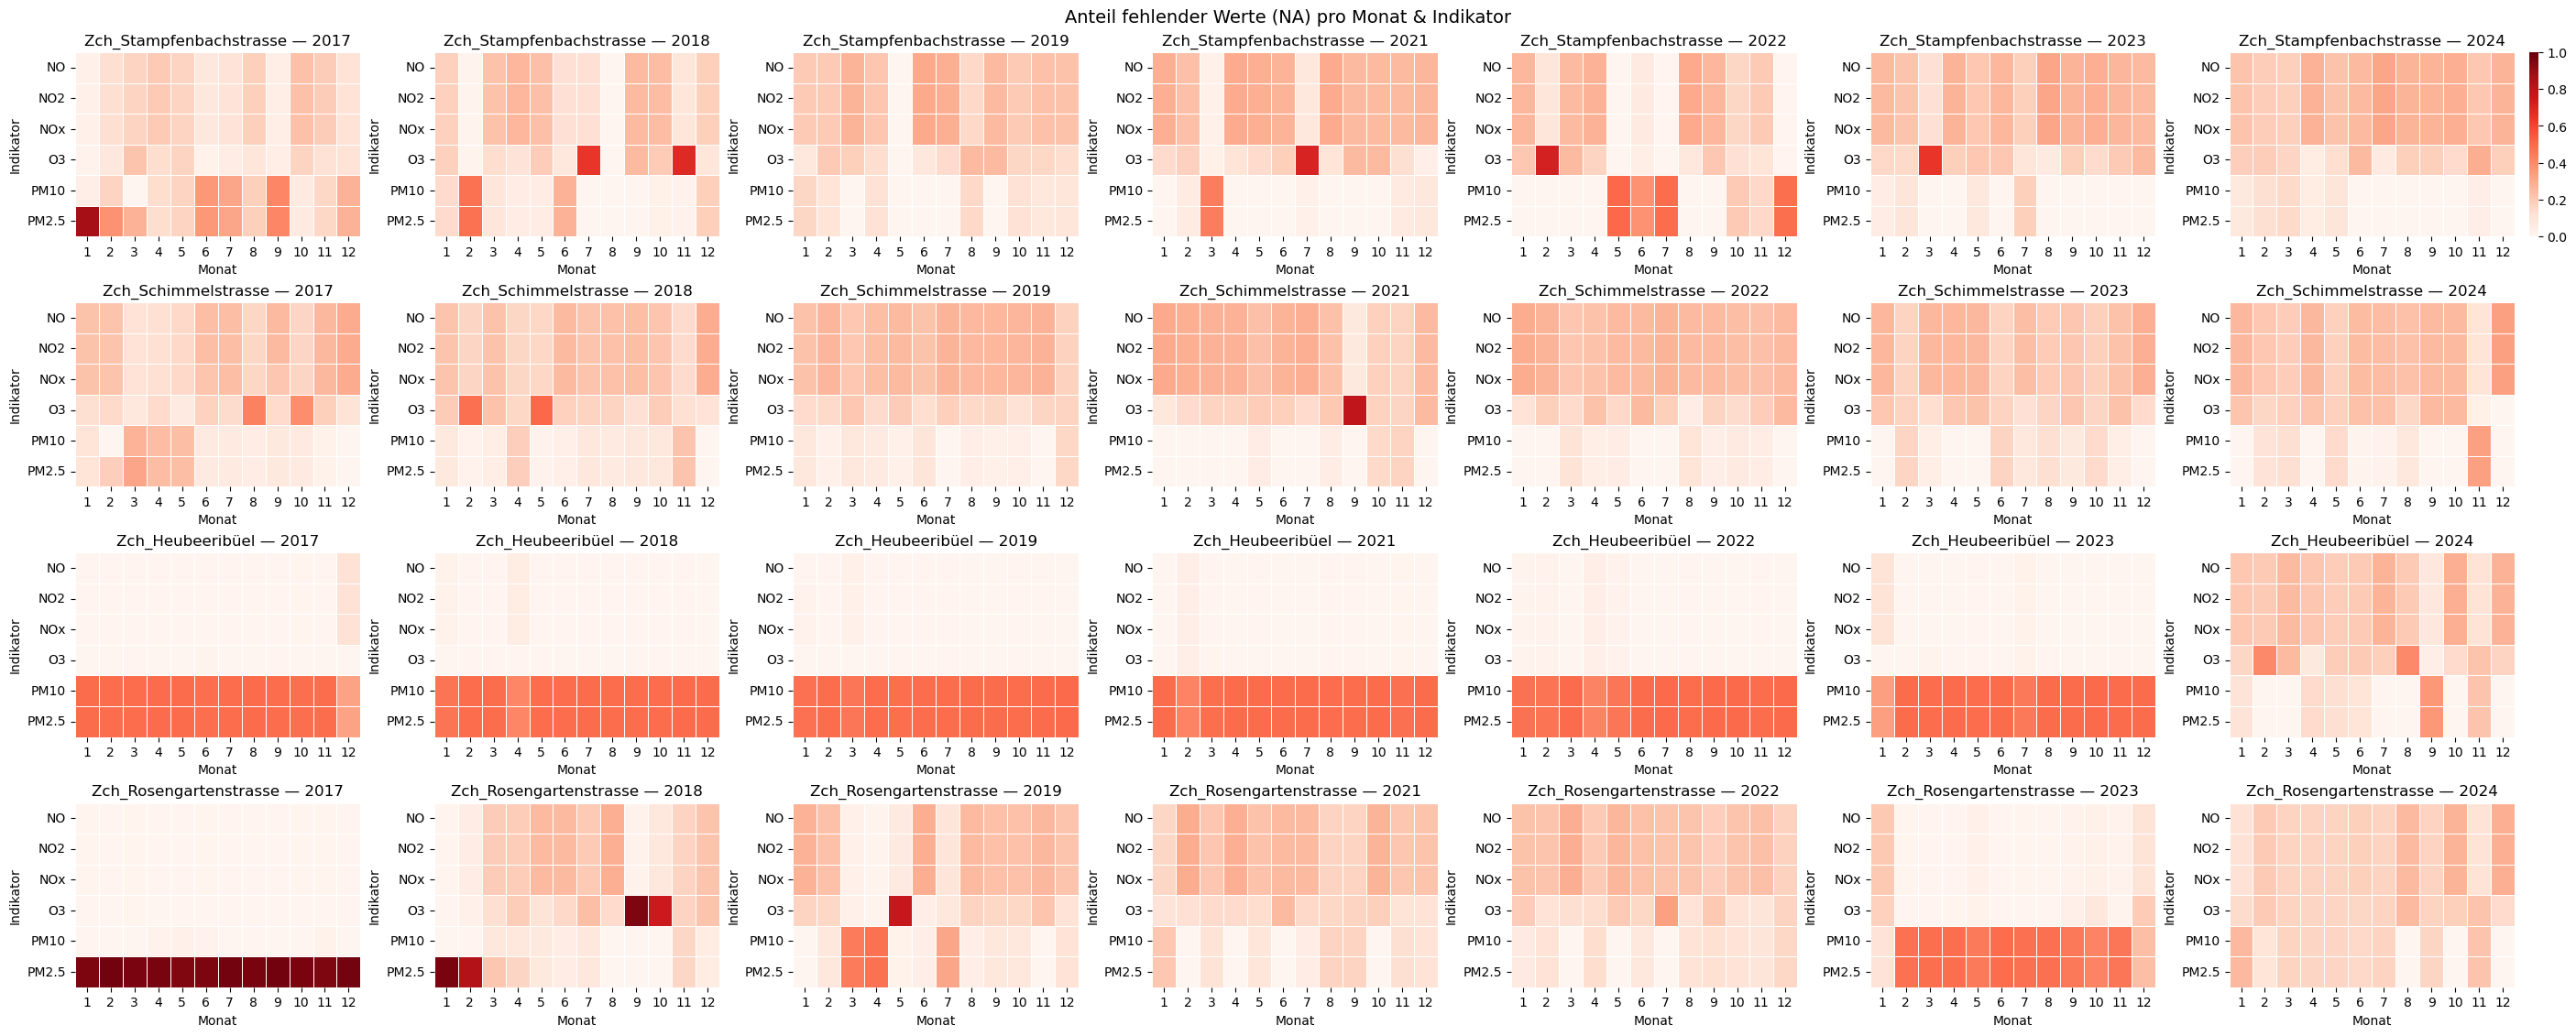

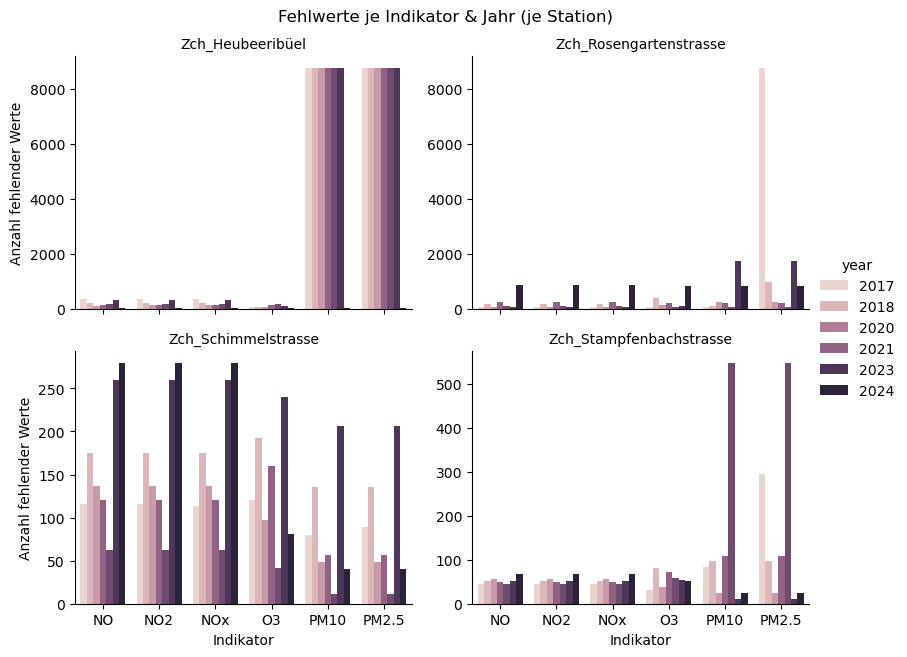

In [ ]:
# =========================
# 1) Build a tidy 'missing' table
# =========================
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_pollutants_pivot.columns]
parameters_cols = [c for c in df_pollutants_pivot.columns if c not in key_cols]
# Melt to long format: one row per (keys, Parameter), with value column 'Wert'
long_vals = df_pollutants_pivot.melt(
    id_vars=key_cols,
    value_vars=parameters_cols,
    var_name="Parameter",
    value_name="Wert"
)

# Keep only rows where the pollutant value is missing
na_long = long_vals[long_vals["Wert"].isna()].drop(columns="Wert").reset_index(drop=True)
na_long

# Choose your parameters & stations
PARAMS = ["NO", "NO2", "NOx", "O3", "PM10", "PM2.5"]  # adjust to taste
stations_all = na_long["Standort"].unique().tolist()
STATIONS5 = stations_all[:4]  # or explicitly pick the four you want

# Prepare year/month
na_long["date_ts"] = pd.to_datetime(na_long["Datum_date"], errors="coerce")
na_long["year"] = na_long["date_ts"].dt.year
na_long["month"] = na_long["date_ts"].dt.month

# Filter to desired subset
miss_sub = na_long[na_long["Standort"].isin(STATIONS5) & na_long["Parameter"].isin(PARAMS)].copy()

# 1) Monthly heatmap: missing rate per (station, year, month, parameter)
# We need denominators (how many expected rows per month) — in a daily matrix it’s one per day, in hourly 24/day.
# Using `mean` of boolean is fine if your pivot has one row per day; if hourly, it is fraction of hours missing in that month.

monthly_rate = (
    miss_sub.groupby(["Standort", "year", "month", "Parameter"], dropna=True)
            .size()                              # count of missing entries
            .reset_index(name="missing_count")
)

# To get rates, we need total expected entries per (station, year, month, parameter).
# If the pivot is daily with one row per day per station, total days per month:
days_per_month = (
    na_long.groupby(["Standort", "year", "month"])
           .size()
           .reset_index(name="total_rows_month")  # total rows across all params; we'll assume same for each param
)

monthly_rate = monthly_rate.merge(days_per_month, on=["Standort", "year", "month"], how="left")
monthly_rate["missing_rate"] = monthly_rate["missing_count"] / monthly_rate["total_rows_month"]

# Fill in missing combinations to show zeros in the heatmap
full_index = pd.MultiIndex.from_product(
    [STATIONS5, sorted(miss_sub["year"].dropna().unique()), range(1,13), PARAMS],
    names=["Standort", "year", "month", "Parameter"]
).to_frame(index=False)

monthly_rate = full_index.merge(monthly_rate,
                                on=["Standort", "year", "month", "Parameter"],
                                how="left").fillna({"missing_rate": 0.0})

# Plot grid: rows = stations, cols = years
years_sorted = sorted(monthly_rate["year"].unique())
nrows, ncols = len(STATIONS5), len(years_sorted)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                         figsize=(4*ncols, 2.8*nrows), constrained_layout=True)

# Ensure axes is 2D
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = axes.reshape(1, -1)

for i, st in enumerate(STATIONS5):
    for j, yr in enumerate(years_sorted):
        ax = axes[i, j]
        mat = (
            monthly_rate[(monthly_rate["Standort"] == st) & (monthly_rate["year"] == yr)]
            .pivot(index="Parameter", columns="month", values="missing_rate")
            .reindex(index=PARAMS)
        )
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap="Reds",
                    cbar=(i==0 and j==ncols-1), linewidths=0.5, linecolor="white")
        ax.set_title(f"{st} — {yr}")
        ax.set_xlabel("Monat")
        ax.set_ylabel("Indikator")
        ax.set_xticklabels([str(m) for m in range(1, 13)], rotation=0)

fig.suptitle("Anteil fehlender Werte (NA) pro Monat & Indikator", fontsize=14)
plt.show()

# 2) Grouped bar chart: counts per pollutant per station, hue = year
counts = (
    miss_sub.groupby(["Standort", "Parameter", "year"], dropna=True)
            .size()
            .reset_index(name="missing_count")
)

g = sns.catplot(
    data=counts, x="Parameter", y="missing_count", hue="year", col="Standort",
    kind="bar", col_wrap=2, sharey=False, height=3.2, aspect=1.3
)
g.set_titles("{col_name}")
g.set_axis_labels("Indikator", "Anzahl fehlender Werte")
plt.suptitle("Fehlwerte je Indikator & Jahr (je Station)", y=1.02)
plt.show()

In [35]:
# check time during summer time
df_pollutants.loc[df_pollutants['Datum'].dt.date == pd.to_datetime('2024-06-18').date(), 'Datum']

1356283   2024-06-18 00:00:00+01:00
1356284   2024-06-18 00:00:00+01:00
1356285   2024-06-18 00:00:00+01:00
1356286   2024-06-18 00:00:00+01:00
1356287   2024-06-18 00:00:00+01:00
                     ...           
1356902   2024-06-18 23:00:00+01:00
1356903   2024-06-18 23:00:00+01:00
1356904   2024-06-18 23:00:00+01:00
1356905   2024-06-18 23:00:00+01:00
1356906   2024-06-18 23:00:00+01:00
Name: Datum, Length: 624, dtype: datetime64[ns, UTC+01:00]

In [ ]:
# check time during summer time
df_pollutants.loc[df_pollutants['Datum'].dt.date == pd.to_datetime('2024-06-18').date(), 'Datum']

1356283   2024-06-18 00:00:00+01:00
1356284   2024-06-18 00:00:00+01:00
1356285   2024-06-18 00:00:00+01:00
1356286   2024-06-18 00:00:00+01:00
1356287   2024-06-18 00:00:00+01:00
                     ...           
1356902   2024-06-18 23:00:00+01:00
1356903   2024-06-18 23:00:00+01:00
1356904   2024-06-18 23:00:00+01:00
1356905   2024-06-18 23:00:00+01:00
1356906   2024-06-18 23:00:00+01:00
Name: Datum, Length: 624, dtype: datetime64[ns, UTC+01:00]

In [49]:
df_pollutants_pivot.to_csv("data/pollutants_h1_17_24.csv", index=False)